In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(327, 1111)


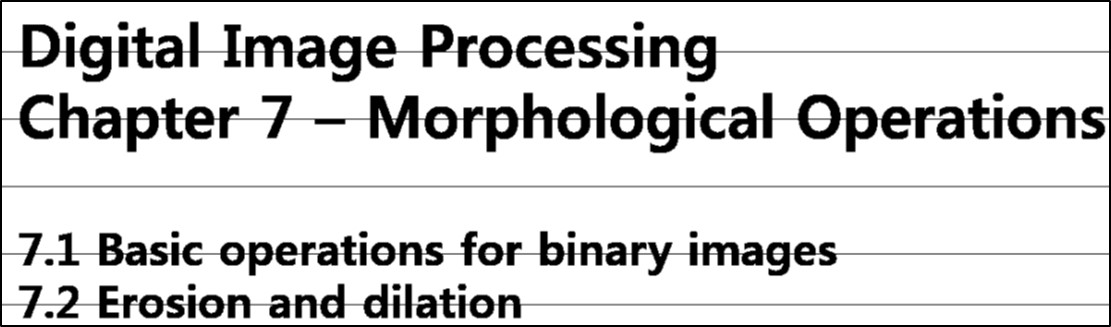

In [2]:
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/scanimg.jpg')
gimg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(gimg.shape)
cv2_imshow(gimg)

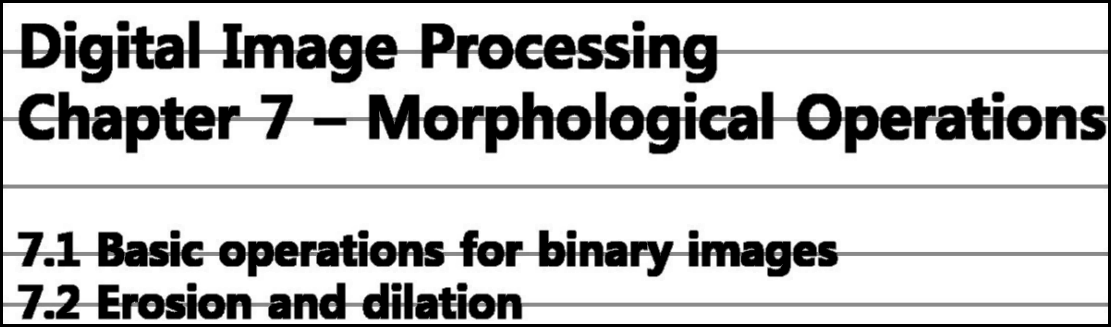

In [3]:
kernel = np.ones((3, 3),np.uint8)
erosed = cv2.erode(gimg,kernel,iterations = 1)
cv2_imshow(erosed)

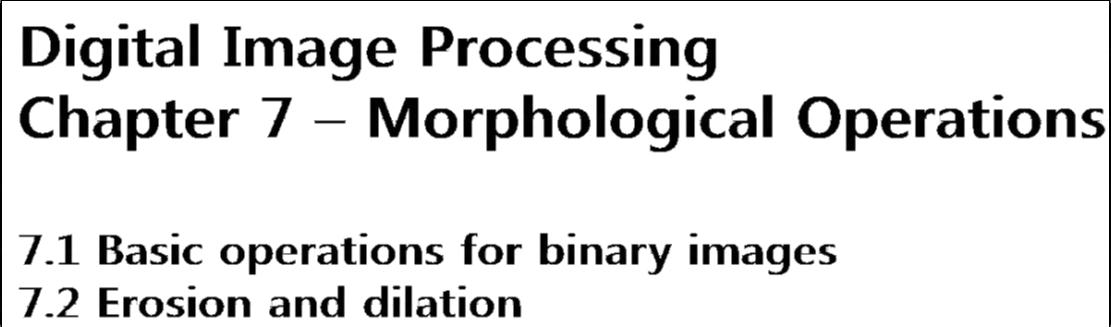

In [6]:
kernel = np.ones((4, 1),np.uint8)
dilated = cv2.dilate(gimg,kernel,iterations = 1)
cv2_imshow(dilated)

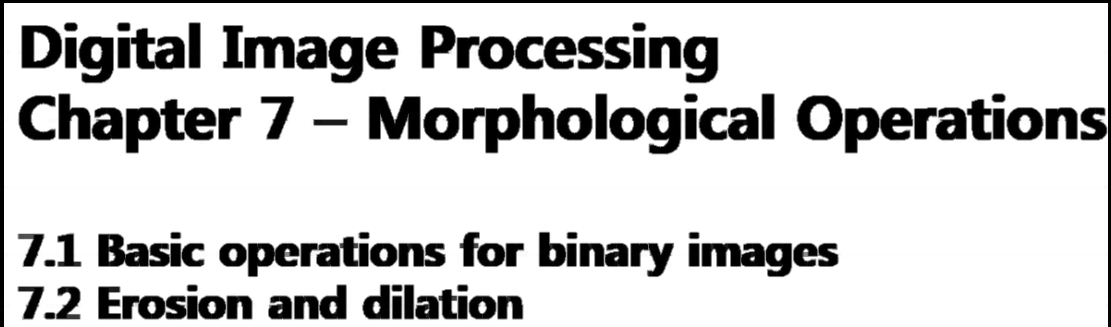

In [11]:
kernel = np.ones((4, 4),np.uint8)
eroded = cv2.erode(dilated,kernel,iterations = 1)
cv2_imshow(eroded)

(256, 256)


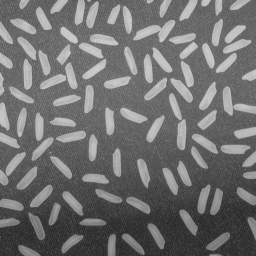

In [12]:
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/rice.bmp')
gimg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(gimg.shape)
cv2_imshow(gimg)

In [13]:
gBin = np.zeros((gimg.shape[0], gimg.shape[1]))

자동 계산된 최적 임계값: 131.0


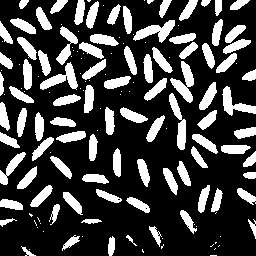

In [16]:
# 오츠의 알고리즘을 사용해 이미지 전체에서 최적의 임계값(Threshold)을 자동으로 찾습니다.
# 쌀알의 소실을 최소화하기 위해 자동 계산된 임계값을 사용합니다.
otsu_threshold, _ = cv2.threshold(gimg, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"자동 계산된 최적 임계값: {otsu_threshold}")

# 기존 코드 흐름을 유지하며 찾은 임계값(otsu_threshold)을 적용합니다.
for i in range(gimg.shape[0]):
  for j in range(gimg.shape[1]):
    if gimg[i,j] > otsu_threshold:
      gBin[i,j] = 255
    else:
      gBin[i,j] = 0

cv2_imshow(gBin)

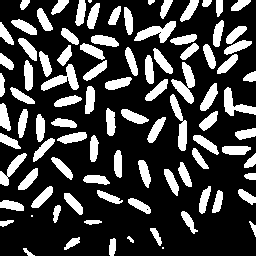

In [17]:
# 쌀알의 소실을 방지하기 위해 더 작은 크기의 커널(2x2)을 사용하거나 열기(Opening) 연산을 적용합니다.
kernel = np.ones((2, 2), np.uint8)

# 침식 후 팽창(열기 연산)을 통해 미세한 노이즈만 제거하고 쌀알 크기는 최대한 유지합니다.
erosed = cv2.erode(gBin, kernel, iterations = 1)
# 원하신다면 깎인 부분을 다시 메우기 위해 팽창(dilate)을 연이어 수행할 수 있습니다.
opened = cv2.dilate(erosed, kernel, iterations = 1)

cv2_imshow(opened)

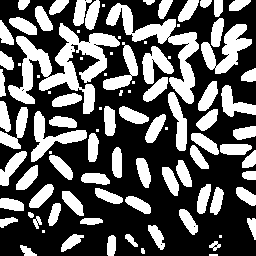

In [20]:
# 쌀알 이미지(gBin)에 대해 팽창(Dilation) 연산을 적용합니다.
kernel_rice = np.ones((3, 3), np.uint8)
rice_dilated = cv2.dilate(gBin.astype(np.uint8), kernel_rice, iterations=1)

# 팽창 연산이 적용된 쌀알 이미지 출력
cv2_imshow(rice_dilated)

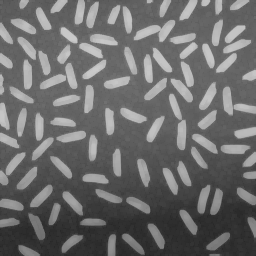

In [21]:
kernel = np.ones((3,3), np.uint8)
openimg = cv2.morphologyEx(gimg, cv2.MORPH_OPEN, kernel)
cv2_imshow(openimg)

In [18]:
# gBin의 데이터 타입을 uint8로 변환하여 connectedComponents에 적용합니다.
gBin_uint8 = opened.astype(np.uint8)

# 연결 성분 분석 (8-way connectivity)
num_labels, labels = cv2.connectedComponents(gBin_uint8, connectivity=8)

# 결과 출력 (라벨 개수에서 배경 1을 제외한 값이 실제 쌀알 개수입니다)
print(f"검출된 총 쌀알 개수: {num_labels - 1}")

검출된 총 쌀알 개수: 94
